In [6]:
import POSEIDON
import numpy as np
import pickle
import spectres
from tqdm import tqdm
from POSEIDON.core import (create_star, create_planet,define_model, make_atmosphere,compute_spectrum, read_opacities,wl_grid_constant_R)
from POSEIDON.constants import R_J, R_Sun, M_J
from POSEIDON.chemistry import load_chemistry_grid
import scipy.constants as sc
import matplotlib.pyplot as plt

In [7]:
spectra_eq = np.load('equi_chem_data/eq_chemistry_spectra.npy')
params_eq  = np.load('equi_chem_data/eq_chemistry_params.npy')

# NOTE: wl_binned is shared with the free-chemistry dataset because both were
# generated with the same wl_grid_constant_R() call. If either dataset is ever
# regenerated with a different wl_min/wl_max/R, this load will silently return
# the wrong wavelength grid (shapes would still match at 52 bins).
wl_binned  = np.load('free_chem_data/wl_binned.npy')

param_names_eq = ['Rstar_Rs', 'Rp_Rj', 'Mp_Mj','T', 'log_Met', 'C_to_O']

print(f"Spectra shape  : {spectra_eq.shape}")
print(f"Params shape   : {params_eq.shape}")
print(f"Wavelength bins: {len(wl_binned)}")

# Sanity check: wl_binned must match the number of wavelength bins in spectra_eq
assert len(wl_binned) == spectra_eq.shape[1], (
    "wl_binned length doesn't match spectra_eq's bin count -- "
    "the free-chem and equi-chem grids may have diverged."
)

Spectra shape  : (113176, 52)
Params shape   : (113176, 6)
Wavelength bins: 52


In [8]:
param_species = ['H2O', 'CH4', 'CO', 'CO2', 'NH3']
bulk_species  = ['H2', 'He']

mol_names   = ['H2O', 'CH4', 'CO', 'CO2', 'NH3']

# Derived, not hardcoded: atm['X'] always stores bulk species first (in
# bulk_species order), then param_species in the order passed to define_model().
# len(bulk_species) == 2 here, so the param species block starts at index 2.
mol_indices = [len(bulk_species) + param_species.index(mol) for mol in mol_names]

mol_colors  = {
    'H2O': 'steelblue',
    'CH4': 'darkorange',
    'CO' : 'green',
    'CO2': 'crimson',
    'NH3': 'purple'
}

# Pressure grid -- same as generation
P = np.logspace(np.log10(10.0), np.log10(1e-7), 100)

# Load chemistry grid once
chemistry_grid = load_chemistry_grid(param_species, grid='fastchem')
print("Setup complete.")
print(f"Pressure grid: {len(P)} layers, "f"{P.max():.0f} to {P.min():.2e} bar")
print(f"mol_indices  : {dict(zip(mol_names, mol_indices))}")

Reading in database for equilibrium chemistry model...
Setup complete.
Pressure grid: 100 layers, 10 to 1.00e-07 bar
mol_indices  : {'H2O': 2, 'CH4': 3, 'CO': 4, 'CO2': 5, 'NH3': 6}


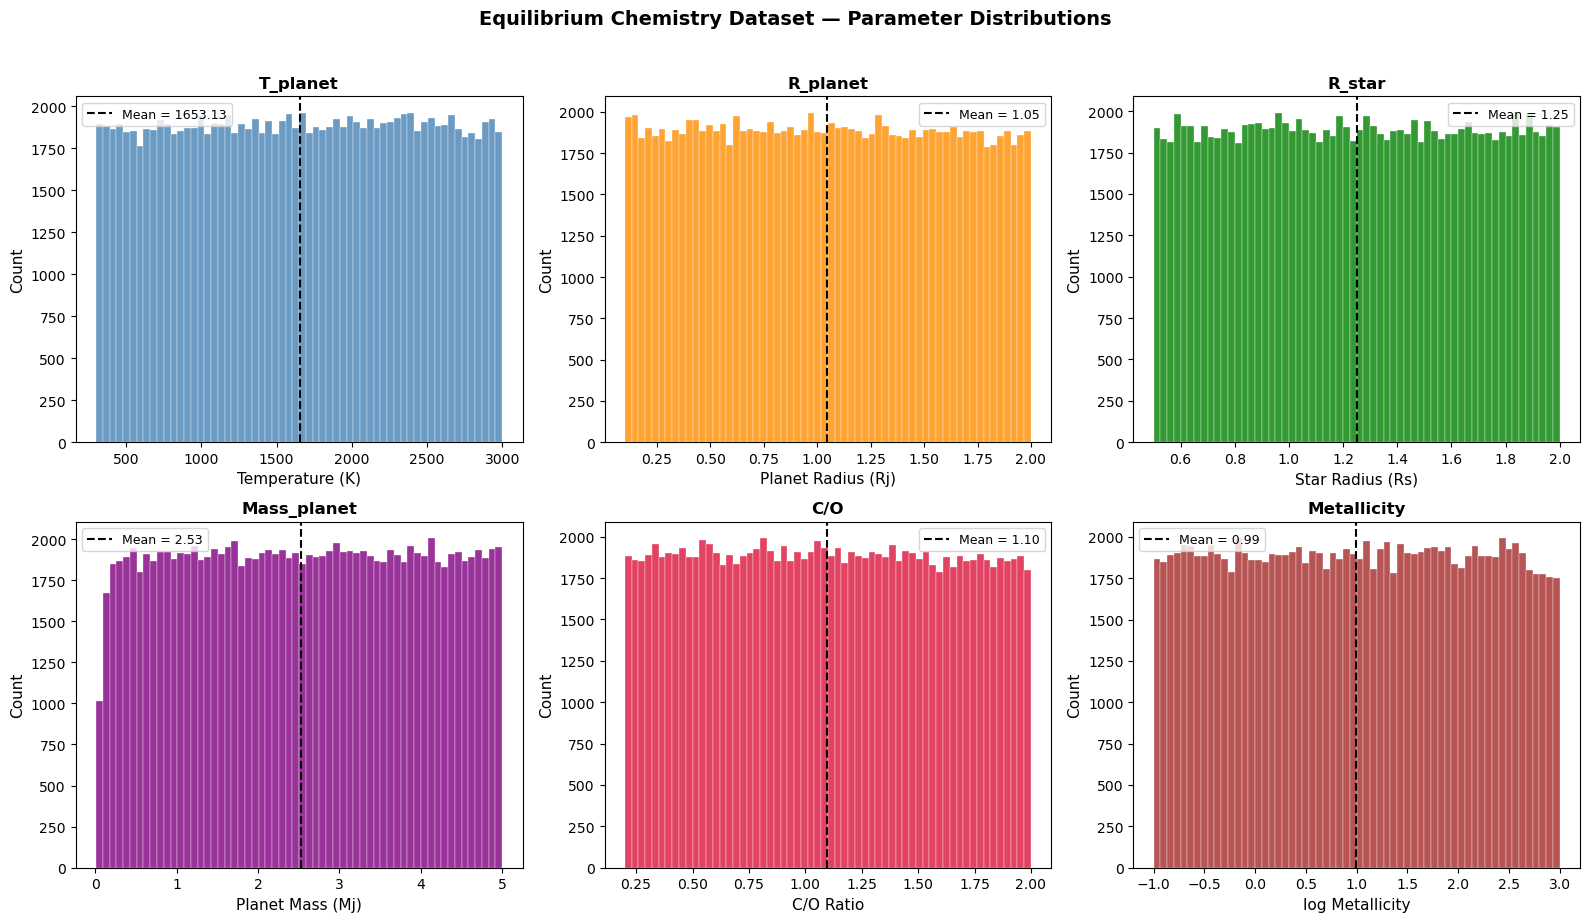

Plot 1 done


In [9]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

plot_config = [
    (3, 'Temperature (K)',    'T_planet',    'steelblue'),
    (1, 'Planet Radius (Rj)', 'R_planet',    'darkorange'),
    (0, 'Star Radius (Rs)',   'R_star',      'green'),
    (2, 'Planet Mass (Mj)',   'Mass_planet', 'purple'),
    (5, 'C/O Ratio',          'C/O',         'crimson'),
    (4, 'log Metallicity',    'Metallicity', 'brown'),
]

for ax, (col_idx, xlabel, title, color) in zip(axes, plot_config):
    vals = params_eq[:, col_idx]
    ax.hist(vals, bins=60, color=color,edgecolor='white', alpha=0.8,linewidth=0.3)
    ax.axvline(vals.mean(), color='black',linestyle='--', linewidth=1.5,label=f'Mean = {vals.mean():.2f}')
    ax.set_xlabel(xlabel, fontsize=11)
    ax.set_ylabel('Count', fontsize=11)
    ax.set_title(title, fontsize=12,fontweight='bold')
    ax.legend(fontsize=9)

plt.suptitle('Equilibrium Chemistry Dataset — ''Parameter Distributions',fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('diag_plot1_param_distributions.png',dpi=150, bbox_inches='tight')
plt.show()
print("Plot 1 done")

In [10]:
np.random.seed(99)
sample_idx = np.random.choice(len(params_eq),10, replace=False)
atm_list   = []
param_list = []

print("Regenerating 10 atmospheres...")
for idx in sample_idx:
    Rstar_Rs, Rp_Rj, Mp_Mj, T, log_Met, C_to_O = \
        params_eq[idx]

    R_p = Rp_Rj * R_J
    M_p = Mp_Mj * M_J
    g_p = (sc.G * M_p) / (R_p ** 2)

    planet = create_planet('p', R_p,gravity=g_p, T_eq=T)
    model  = define_model('m', bulk_species,param_species,PT_profile='isotherm',X_profile='chem_eq')
    PT_params = np.array([T])
    X_params  = np.array([C_to_O, log_Met])

    atm = make_atmosphere(planet, model, P,10.0, R_p,PT_params, X_params,chemistry_grid=chemistry_grid)
    atm_list.append(atm)
    param_list.append(params_eq[idx])

print(f"Done. {len(atm_list)} atmospheres ready.")

Regenerating 10 atmospheres...
Done. 10 atmospheres ready.


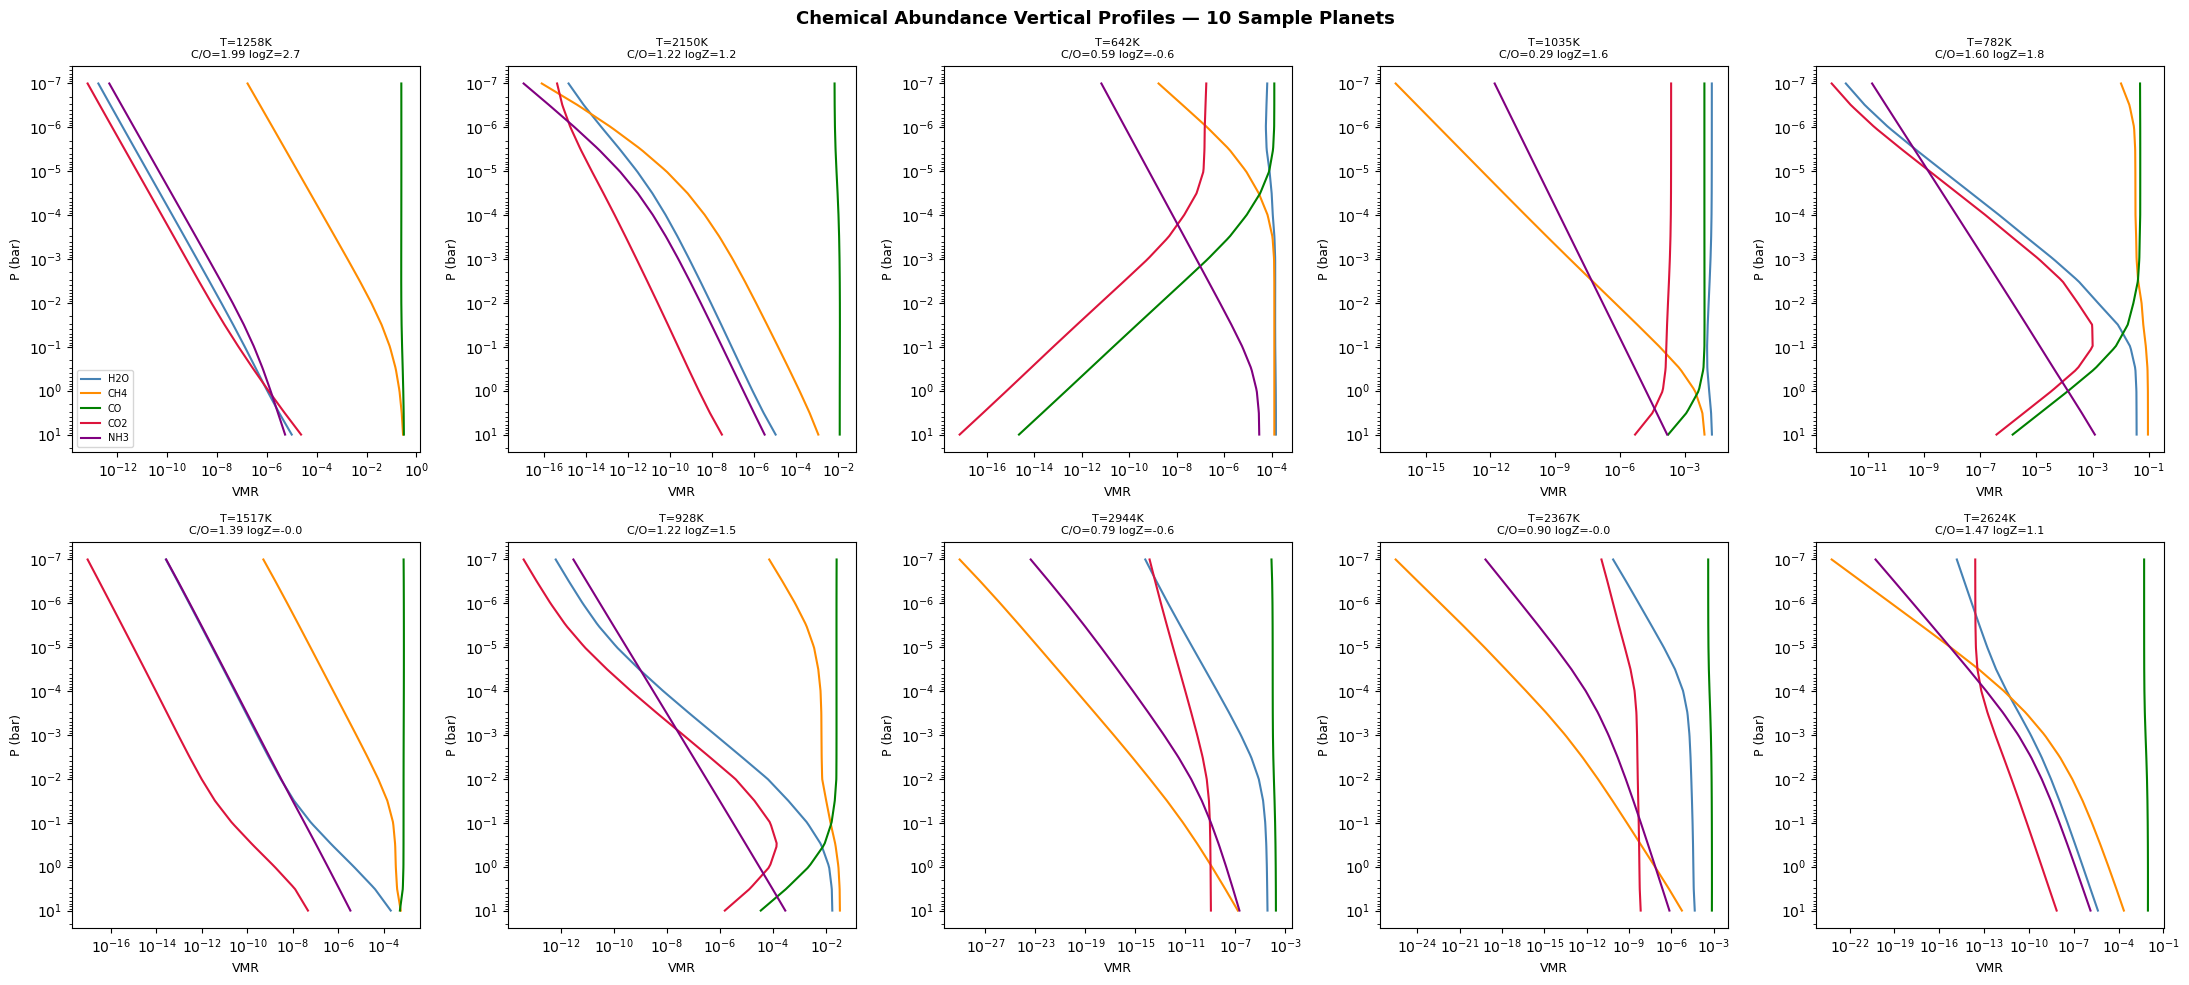

Plot 2 done


In [11]:
fig, axes = plt.subplots(2, 5, figsize=(22, 10))

for planet_idx in range(10):
    row = planet_idx // 5
    col = planet_idx  % 5
    ax  = axes[row][col]

    atm = atm_list[planet_idx]
    par = param_list[planet_idx]

    for mol, mol_idx in zip(mol_names, mol_indices):
        vmr = atm['X'][mol_idx, :, 0, 0]
        vmr = np.where(vmr <= 0, 1e-30, vmr)

        ax.plot(vmr, P,color=mol_colors[mol],label=mol,linewidth=1.5)

    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.invert_yaxis()
    ax.set_xlabel('VMR', fontsize=9)
    ax.set_ylabel('P (bar)', fontsize=9)
    ax.set_title(f'T={par[3]:.0f}K\n'f'C/O={par[5]:.2f} logZ={par[4]:.1f}',fontsize=8)
    if planet_idx == 0:
        ax.legend(fontsize=7, loc='lower left')

plt.suptitle('Chemical Abundance Vertical Profiles'' — 10 Sample Planets',fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('diag_plot2_vmr_profiles.png',dpi=150, bbox_inches='tight')
plt.show()
print("Plot 2 done")

In [12]:
from POSEIDON.chemistry import interpolate_log_X_grid

# Find pressure layer closest to 100 mbar (kept only for the printed sanity
# check below -- the interpolator uses P_target directly, not the discretised
# P grid, so this index is no longer used for the extraction itself)
P_target = 0.1
P_idx    = np.argmin(np.abs(P - P_target))
print(f"Using layer {P_idx}: P = {P[P_idx]:.4f} bar")

# Use 10,000 planet subsample for speed
N_sample    = 10000
np.random.seed(42)
sample_idx3 = np.random.choice(len(params_eq), N_sample, replace=False)

# Pull out only the 3 columns interpolate_log_X_grid needs, for all 10,000
# planets at once. params_eq columns are
# [Rstar_Rs, Rp_Rj, Mp_Mj, T, log_Met, C_to_O].
T_batch       = params_eq[sample_idx3, 3]
log_Met_batch = params_eq[sample_idx3, 4]
C_to_O_batch  = params_eq[sample_idx3, 5]

# Single scalar pressure (log10 bar), shared across the whole batch
log_P_target = np.log10(P_target)

print(f"Extracting VMRs at 100 mbar for {N_sample} planets (vectorized)...")

# One interpolation call replaces the 10,000-iteration loop that rebuilt a
# full atmosphere each time. interpolate_log_X_grid wraps a
# RegularGridInterpolator over the chemistry grid, so it accepts array
# inputs for T / C_to_O / log_Met directly.
log_X_dict = interpolate_log_X_grid(
    chemistry_grid,
    log_P=log_P_target,
    T=T_batch,
    C_to_O=C_to_O_batch,
    log_Met=log_Met_batch,
    chemical_species=np.array(mol_names),   # must be an array, not a list
    return_dict=True
)

# log_X_dict holds log10(VMR) per species -- convert back to linear VMR to
# match the units atm['X'] used elsewhere in the notebook.
vmr_at_100mbar = {mol: 10**log_X_dict[mol] for mol in mol_names}

print("Extraction complete.")
for mol in mol_names:
    vals = vmr_at_100mbar[mol]
    print(f"{mol}: min={vals.min():.2e} "f"max={vals.max():.2e} "f"mean={vals.mean():.2e}")

Using layer 25: P = 0.0955 bar
Extracting VMRs at 100 mbar for 10000 planets (vectorized)...
Extraction complete.
H2O: min=1.99e-16 max=3.61e-01 mean=1.15e-02
CH4: min=3.50e-14 max=5.29e-01 mean=1.60e-02
CO: min=3.29e-31 max=3.98e-01 mean=3.85e-02
CO2: min=1.68e-30 max=1.97e-01 mean=1.73e-03
NH3: min=1.30e-17 max=4.10e-02 mean=1.82e-04


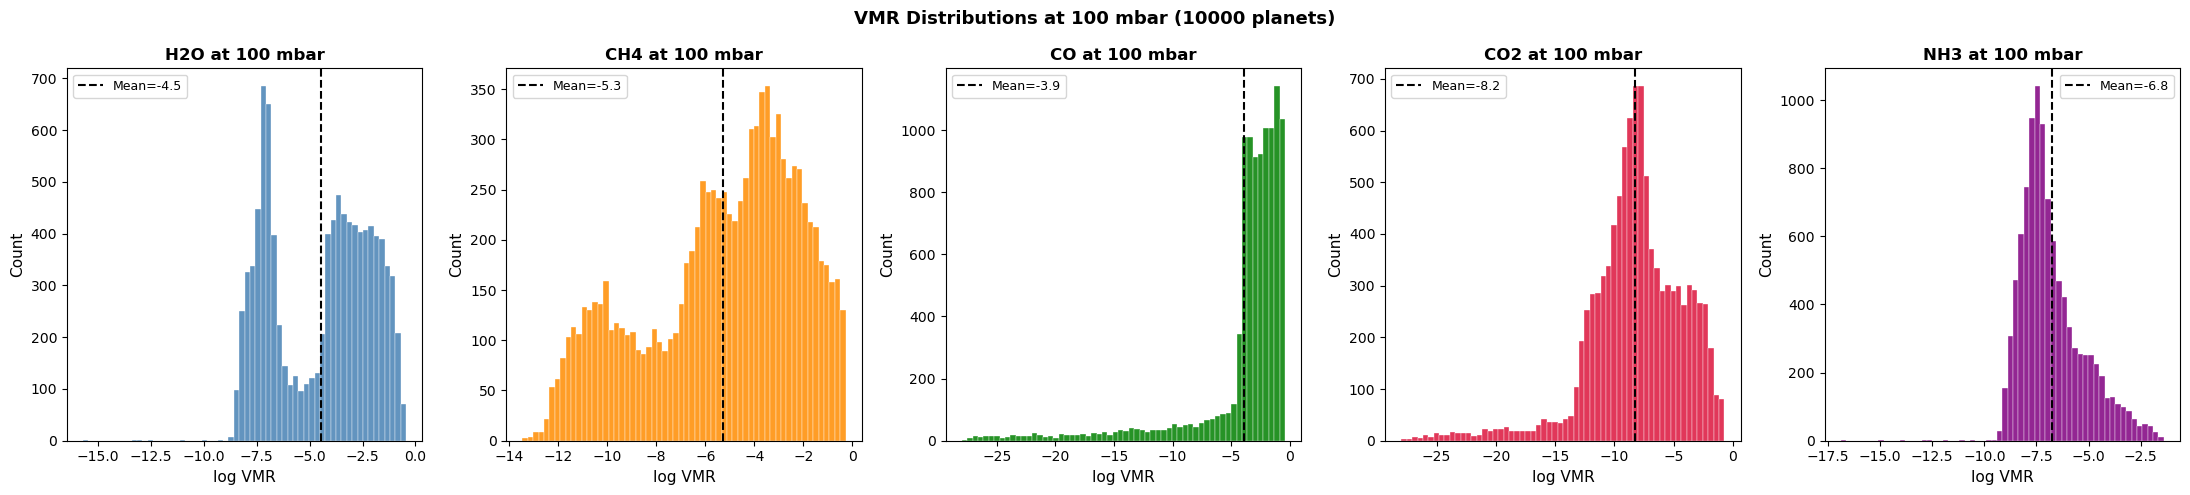

Plot 3 done


In [13]:
fig, axes = plt.subplots(1, 5, figsize=(22, 5))

for ax, mol in zip(axes, mol_names):
    raw  = vmr_at_100mbar[mol]
    raw  = np.where(raw <= 0, 1e-30, raw)
    vals = np.log10(raw)
    vals = vals[vals > -28]   # remove placeholder zeros

    ax.hist(vals, bins=60,color=mol_colors[mol],edgecolor='white',alpha=0.85, linewidth=0.3)
    ax.axvline(vals.mean(), color='black',   linestyle='--', linewidth=1.5,   label=f'Mean={vals.mean():.1f}')
    ax.set_xlabel('log VMR', fontsize=11)
    ax.set_ylabel('Count', fontsize=11)
    ax.set_title(f'{mol} at 100 mbar',     fontsize=12, fontweight='bold')
    ax.legend(fontsize=9)

plt.suptitle(f'VMR Distributions at 100 mbar ' f'({N_sample} planets)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('diag_plot3_vmr_histograms.png',dpi=150, bbox_inches='tight')
plt.show()
print("Plot 3 done")

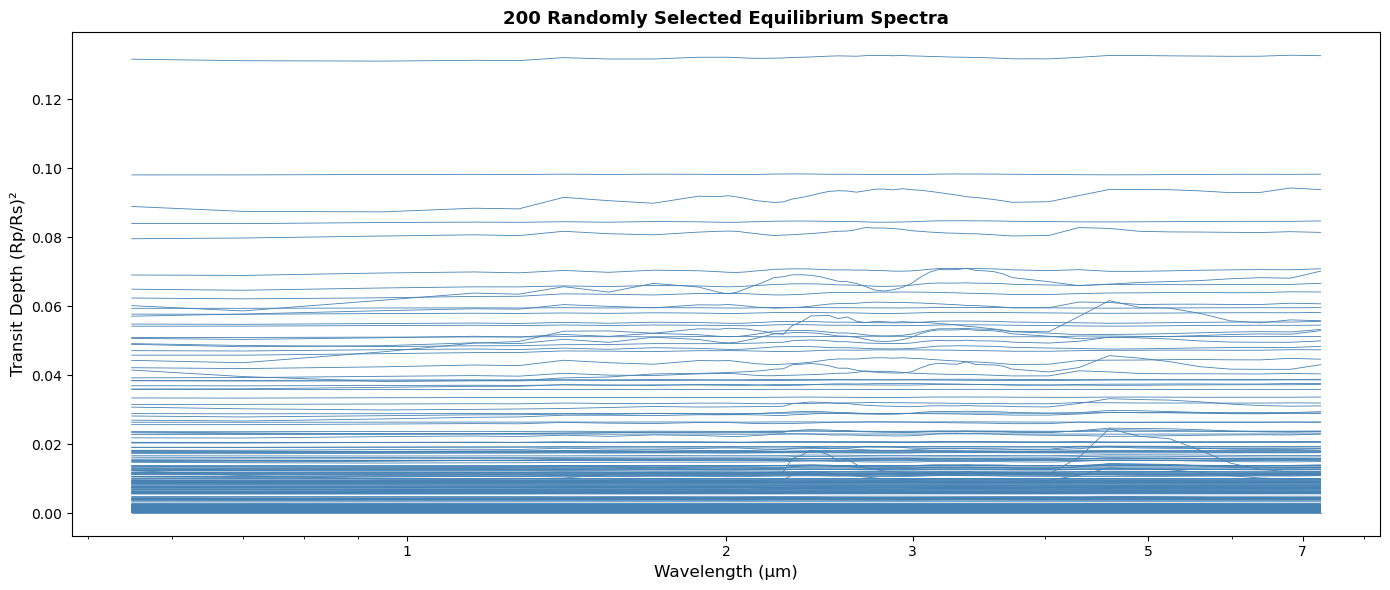

Plot 4 done


In [14]:
def set_log_wavelength_ticks(ax, wl):
    """Force readable major tick labels on a log-scaled wavelength axis.

    matplotlib's default log locator only labels powers of 10, which means
    a grid spanning ~0.3-5 um only ever shows a single '10^0' tick. This picks
    round-number ticks that actually fall inside the data's wavelength range.
    """
    wl_min, wl_max = wl.min(), wl.max()
    candidate_ticks = [0.3, 0.5, 1, 2, 3, 5, 7, 10]
    ticks = [t for t in candidate_ticks if wl_min <= t <= wl_max]
    ax.set_xticks(ticks)
    ax.set_xticklabels([str(t) for t in ticks])


# -- Plot 4 -- 200 raw spectra --------------------
np.random.seed(7)
idx_200 = np.random.choice(len(spectra_eq), 200, replace=False)

fig, ax = plt.subplots(figsize=(14, 6))
for i in idx_200:
    ax.plot(wl_binned, spectra_eq[i], alpha=1, linewidth=0.6, color='steelblue')
ax.set_xlabel('Wavelength (μm)', fontsize=12)
ax.set_ylabel('Transit Depth (Rp/Rs)²', fontsize=12)
ax.set_title('200 Randomly Selected Equilibrium Spectra', fontsize=13, fontweight='bold')
ax.set_xscale('log')
set_log_wavelength_ticks(ax, wl_binned)
plt.tight_layout()
plt.savefig('diag_plot4_200_spectra.png', dpi=150, bbox_inches='tight')
plt.show()
print("Plot 4 done")

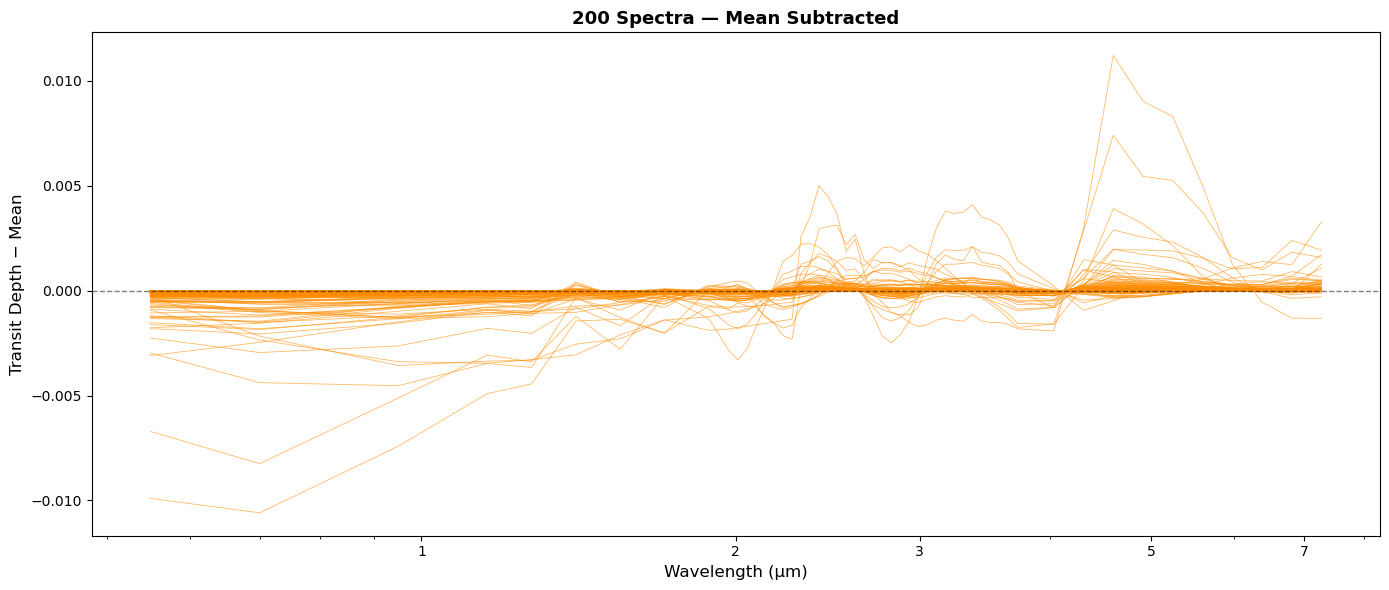

Plot 5 done


In [15]:
# -- Plot 5 -- mean subtracted --------------------
fig, ax = plt.subplots(figsize=(14, 6))
for i in idx_200:
    spec = spectra_eq[i]
    ax.plot(wl_binned, spec - spec.mean(), alpha=0.6, linewidth=0.6, color='darkorange')
ax.axhline(0, color='black', linewidth=1, linestyle='--', alpha=0.5)
ax.set_xlabel('Wavelength (μm)', fontsize=12)
ax.set_ylabel('Transit Depth − Mean', fontsize=12)
ax.set_title('200 Spectra — Mean Subtracted', fontsize=13, fontweight='bold')
ax.set_xscale('log')
set_log_wavelength_ticks(ax, wl_binned)
plt.tight_layout()
plt.savefig('diag_plot5_mean_centred.png', dpi=150, bbox_inches='tight')
plt.show()
print("Plot 5 done")

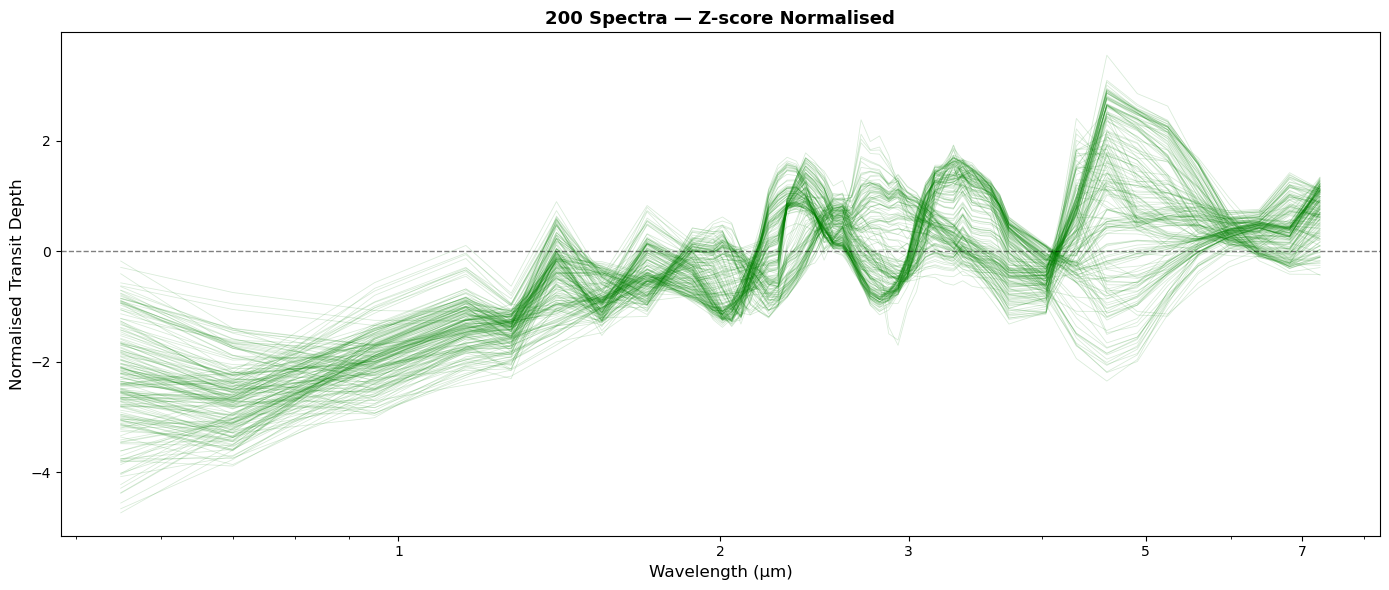

Plot 6 done


In [16]:
# -- Plot 6 -- z-score normalised ---------------
fig, ax = plt.subplots(figsize=(14, 6))
for i in idx_200:
    spec = spectra_eq[i]
    std  = spec.std()
    if std > 0:
        spec_norm = (spec - spec.mean()) / std
        ax.plot(wl_binned, spec_norm, alpha=0.15, linewidth=0.6, color='green')
ax.axhline(0, color='black', linewidth=1, linestyle='--', alpha=0.5)
ax.set_xlabel('Wavelength (μm)', fontsize=12)
ax.set_ylabel('Normalised Transit Depth', fontsize=12)
ax.set_title('200 Spectra — Z-score Normalised', fontsize=13, fontweight='bold')
ax.set_xscale('log')
set_log_wavelength_ticks(ax, wl_binned)
plt.tight_layout()
plt.savefig('diag_plot6_zscore_spectra.png', dpi=150, bbox_inches='tight')
plt.show()
print("Plot 6 done")

Total spectra : 113176
Spectra with depth>1  : 0
Percentage    : 0.000%


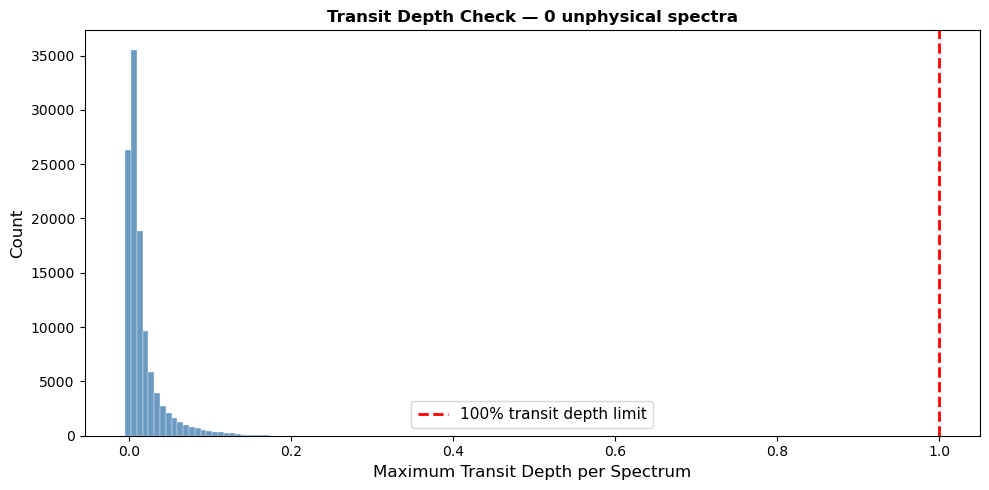

Plot 7 done — 0 bad spectra
All 113176 spectra were already physically valid. Saved as-is.


In [17]:
max_depths = spectra_eq.max(axis=1)
bad_mask   = max_depths > 1.0
n_bad      = bad_mask.sum()

print(f"Total spectra : {len(spectra_eq)}")
print(f"Spectra with depth>1  : {n_bad}")
print(f"Percentage    : "f"{n_bad/len(spectra_eq)*100:.3f}%")

fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(max_depths, bins=100, color='steelblue', edgecolor='white', alpha=0.8, linewidth=0.3)
ax.axvline(1.0, color='red', linewidth=2, linestyle='--', label='100% transit depth limit')
ax.set_xlabel('Maximum Transit Depth per Spectrum', fontsize=12)
ax.set_ylabel('Count', fontsize=12)
ax.set_title(f'Transit Depth Check — 'f'{n_bad} unphysical spectra', fontsize=12, fontweight='bold')
ax.legend(fontsize=11)
plt.tight_layout()
plt.savefig('diag_plot7_depth_check.png', dpi=150, bbox_inches='tight')
plt.show()
print(f"Plot 7 done — {n_bad} bad spectra")

# Always write the *_clean files, even when nothing was removed -- downstream
# scripts can then rely on these filenames unconditionally instead of
# branching on whether cleaning happened upstream.
spectra_eq_clean = spectra_eq[~bad_mask]
params_eq_clean  = params_eq[~bad_mask]

np.save('eq_chemistry_spectra_clean.npy', spectra_eq_clean)
np.save('eq_chemistry_params_clean.npy',  params_eq_clean)

if n_bad > 0:
    print(f"Removed {n_bad} unphysical spectra. Saved {len(spectra_eq_clean)} clean spectra.")
else:
    print(f"All {len(spectra_eq_clean)} spectra were already physically valid. Saved as-is.")